# Segmentação de imagens por cor: de RGB para HSV

**Tutorial de teoria e prática (Projeto 2, Opção 2)**

| Nome completo | RA |
|---|---|
| João Guilherme Messias de Oliveira Santos | 10426110 |
| Luis Felipe Cunha | 10419514 |

Computação Visual, Turma 201815117.000.07N, Prof. André Kishimoto.
Ciência da Computação, Faculdade de Computação e Informática, Universidade Presbiteriana Mackenzie, 2026.2.

## Sumário

1. [Motivação](#secao1)
2. [Cor e o modelo RGB](#secao2)
3. [O modelo HSV e a conversão RGB → HSV](#secao3)
4. [Validação da conversão](#secao4)
5. [Segmentação por faixa de matiz](#secao5)
6. [Comparação: a mesma segmentação em RGB](#secao6)
7. [Limitações](#secao7)
8. [Conclusão](#secao8)
9. [Uso de IA](#secao9)
10. [Referências](#secao10)

## Preparação

Bibliotecas usadas no tutorial. O NumPy guarda as imagens como matrizes, o Matplotlib mostra as imagens e os gráficos, e o Pillow lê os arquivos de imagem. A conversão de cor e a segmentação são implementadas por nós nas próximas seções.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 100

<a id="secao1"></a>

## 1. Motivação

Até aqui, na disciplina, tudo foi feito em escala de cinza: no Projeto 1 convertemos a imagem para cinza antes de calcular o histograma e equalizar, e nos posts do blog trabalhamos com transformações ponto a ponto, suavização e limiarização. Na limiarização, escolhemos um valor e separamos os pixels mais claros dos mais escuros.

Agora a pergunta é outra: **como isolar um objeto pela cor dele?** Por exemplo, "quero só o objeto vermelho da foto". Para isso o cinza não serve, e vamos mostrar o motivo com uma imagem de teste.

### Imagem de teste sintética

Antes de usar fotos, criamos uma imagem pelo próprio código. Como sabemos exatamente onde cada objeto foi desenhado, temos um **gabarito**: mais à frente ele permite medir com números se uma segmentação acertou ou errou.

A cena tem:

- quatro objetos: um círculo vermelho, um quadrado verde, um círculo azul e um quadrado cinza. As cores foram escolhidas para terem **quase o mesmo tom de cinza**;
- um fundo bege claro;
- uma iluminação que escurece um pouco da esquerda para a direita;
- uma **sombra** que cobre a parte de baixo da cena e corta todos os objetos ao meio;
- um pouco de ruído, como acontece numa foto real.

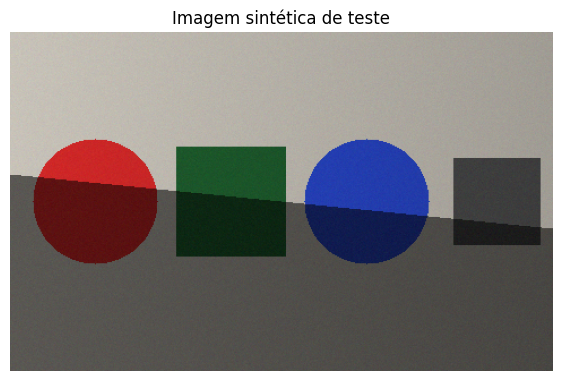

In [2]:
def cria_imagem_sintetica(altura=300, largura=480, semente=0):
    """Devolve a imagem RGB (uint8), o gabarito de cada objeto e a máscara da sombra."""
    y, x = np.mgrid[0:altura, 0:largura]

    cores = {
        "vermelho": (210, 40, 40),
        "verde": (30, 92, 45),
        "azul": (40, 70, 200),
        "cinza": (75, 75, 75),
    }
    gabarito = {
        "vermelho": (x - 75) ** 2 + (y - 150) ** 2 <= 55 ** 2,
        "verde": (np.abs(x - 195) <= 48) & (np.abs(y - 150) <= 48),
        "azul": (x - 315) ** 2 + (y - 150) ** 2 <= 55 ** 2,
        "cinza": (np.abs(x - 430) <= 38) & (np.abs(y - 150) <= 38),
    }

    img = np.empty((altura, largura, 3))
    img[:] = (200, 195, 185)
    for nome, cor in cores.items():
        img[gabarito[nome]] = cor

    # Luz e sombra multiplicam os três canais pelo mesmo fator, como acontece na prática
    sombra = y > 150 + 0.1 * (x - 240)
    fator = (1.0 - 0.2 * x / (largura - 1)) * np.where(sombra, 0.45, 1.0)
    img *= fator[..., None]

    rng = np.random.default_rng(semente)
    img += rng.normal(0, 3, img.shape)
    return np.clip(np.round(img), 0, 255).astype(np.uint8), gabarito, sombra


img_sint, gabarito, sombra = cria_imagem_sintetica()

plt.figure(figsize=(7, 4.5))
plt.imshow(img_sint)
plt.title("Imagem sintética de teste")
plt.axis("off")
plt.show()

### Tentando com a escala de cinza

Convertemos a imagem para cinza com a mesma fórmula do Projeto 1:

$$Y = 0{,}2125\,R + 0{,}7154\,G + 0{,}0721\,B$$

Depois aplicamos um limiar, como na limiarização do blog: os pixels mais escuros que 100 viram objeto.

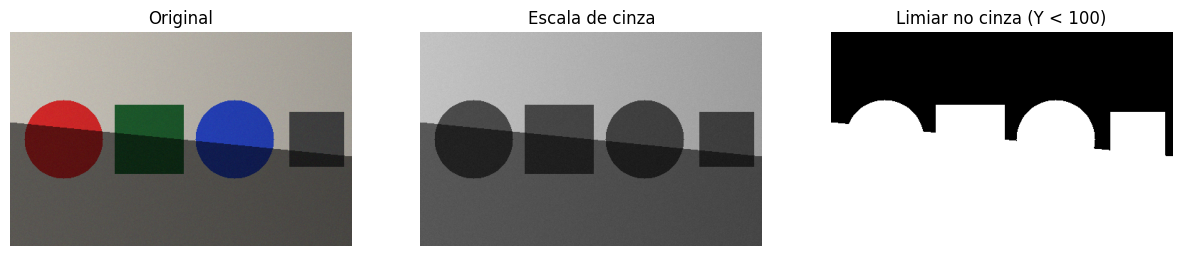

Tom de cinza médio de cada objeto (parte iluminada):
  vermelho    73.7
  verde       69.3
  azul        63.4
  cinza       61.5


In [3]:
def para_cinza(img):
    rgb = img.astype(float)
    return 0.2125 * rgb[..., 0] + 0.7154 * rgb[..., 1] + 0.0721 * rgb[..., 2]


cinza = para_cinza(img_sint)
mascara_cinza = cinza < 100

fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
eixos[0].imshow(img_sint)
eixos[0].set_title("Original")
eixos[1].imshow(cinza, cmap="gray", vmin=0, vmax=255)
eixos[1].set_title("Escala de cinza")
eixos[2].imshow(mascara_cinza, cmap="gray")
eixos[2].set_title("Limiar no cinza (Y < 100)")
for eixo in eixos:
    eixo.axis("off")
plt.show()

print("Tom de cinza médio de cada objeto (parte iluminada):")
for nome, regiao in gabarito.items():
    print(f"  {nome:9s} {cinza[regiao & ~sombra].mean():6.1f}")

Na escala de cinza os quatro objetos têm quase o mesmo tom, entre 60 e 80. Por isso nenhum limiar consegue separar o vermelho do verde: o limiar pega todos os objetos de uma vez e ainda pega a sombra do fundo.

A informação que diferencia os objetos é a **cor**, e ela se perde quando juntamos os três canais num único número. Nas próximas seções vamos trabalhar com os três canais, primeiro em RGB e depois em HSV.

<a id="secao2"></a>

## 2. Cor e o modelo RGB

### Teoria

Na aula de Fundamentos da Imagem Digital vimos que a luz visível vai de cerca de 400 nm (violeta) a 700 nm (vermelho), e que a cor que enxergamos num objeto depende dos comprimentos de onda que ele reflete. Vimos também que os **cones** da retina são as células responsáveis pela percepção de cor.

Existem três tipos de cones, mais sensíveis a comprimentos de onda que percebemos como vermelho, verde e azul (GONZALEZ; WOODS, 2010, cap. 6). Por isso, misturando três luzes primárias, **R** (vermelho), **G** (verde) e **B** (azul), conseguimos reproduzir a maior parte das cores que vemos. Essa é a ideia do **modelo RGB**, usado por câmeras e telas.

- O modelo é **aditivo**: começamos no preto (nenhuma luz) e vamos somando luz. Vermelho + verde = amarelo, e os três no máximo = branco.
- Cada canal costuma ter 8 bits, ou seja, valores de 0 a 255. São $256^3 = 16.777.216$ cores possíveis.
- Podemos imaginar as cores como pontos dentro de um **cubo**: cada eixo é um canal, o preto $(0,0,0)$ fica num canto e o branco $(255,255,255)$ no canto oposto. A diagonal que liga os dois tem $R = G = B$: são os **tons de cinza**.

No computador, uma imagem RGB é uma matriz com três camadas: `altura × largura × 3`. Cada pixel guarda três números.

### Prática: os três canais

In [4]:
print("Formato da imagem:", img_sint.shape, "| tipo:", img_sint.dtype)
print("Pixel (linha 120, coluna 75), no círculo vermelho iluminado:", img_sint[120, 75])
print("Pixel (linha 120, coluna 300), no círculo azul iluminado:   ", img_sint[120, 300])

Formato da imagem: (300, 480, 3) | tipo: uint8
Pixel (linha 120, coluna 75), no círculo vermelho iluminado: [207  37  40]
Pixel (linha 120, coluna 300), no círculo azul iluminado:    [ 33  61 174]


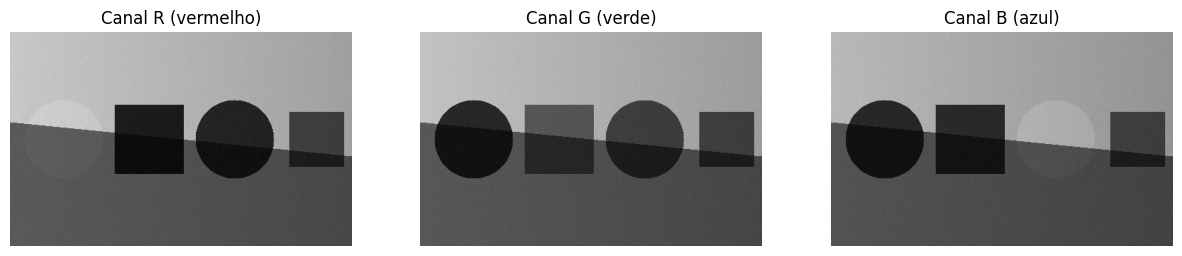

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
for c, (eixo, nome) in enumerate(zip(eixos, ["R (vermelho)", "G (verde)", "B (azul)"])):
    eixo.imshow(img_sint[..., c], cmap="gray", vmin=0, vmax=255)
    eixo.set_title(f"Canal {nome}")
    eixo.axis("off")
plt.show()

Cada canal sozinho é uma imagem em escala de cinza. O círculo vermelho aparece claro no canal R e escuro no G e no B, e o círculo azul aparece claro só no canal B. Mas repare no canal R: a **metade com sombra do círculo vermelho** fica quase tão escura quanto o fundo na sombra.

### A limitação do RGB: a sombra muda os três canais

Uma sombra, ou uma luz mais fraca, reduz a quantidade de luz que chega ao objeto. Isso multiplica os três canais pelo mesmo fator $k < 1$:

$$(R, G, B) \;\rightarrow\; (k\,R,\; k\,G,\; k\,B)$$

A proporção entre os canais, que é o que nos faz dizer "isso é vermelho", continua a mesma. Os **valores** dos três canais, porém, mudam todos juntos. Vamos medir isso nos objetos da imagem sintética:

In [6]:
print(f"{'região':28s} {'R':>6s} {'G':>6s} {'B':>6s}")
for nome in ["vermelho", "verde", "azul"]:
    for parte, onde in [("iluminado", ~sombra), ("na sombra", sombra)]:
        r, g, b = img_sint[gabarito[nome] & onde].mean(axis=0)
        print(f"{nome + ' ' + parte:28s} {r:6.1f} {g:6.1f} {b:6.1f}")

fundo = ~np.any(list(gabarito.values()), axis=0)
r, g, b = img_sint[fundo & sombra].mean(axis=0)
print(f"{'fundo na sombra':28s} {r:6.1f} {g:6.1f} {b:6.1f}")

região                            R      G      B
vermelho iluminado            203.1   38.8   38.8
vermelho na sombra             91.6   17.5   17.4
verde iluminado                27.6   84.5   41.2
verde na sombra                12.4   38.0   18.7
azul iluminado                 34.8   60.8  173.7
azul na sombra                 15.8   27.3   78.3
fundo na sombra                81.1   79.1   75.0


O R do vermelho na sombra (cerca de 90) ficou mais perto do R do fundo na sombra (cerca de 80) do que do R do próprio vermelho iluminado (cerca de 200). Uma regra simples como "é vermelho se R > 150" perde metade do objeto.

O gráfico abaixo mostra cada pixel dos objetos como um ponto no plano R × G (o B fica de fora para o desenho caber em 2D). A linha tracejada liga a origem (o preto) à cor média da parte iluminada de cada objeto. Repare que cada objeto aparece como **dois grupos de pontos sobre a mesma linha**: o grupo longe da origem é a parte iluminada e o grupo perto da origem é a parte na sombra. Numa foto real a sombra costuma ser gradual, e o espaço entre os dois grupos fica preenchido, formando uma faixa contínua.

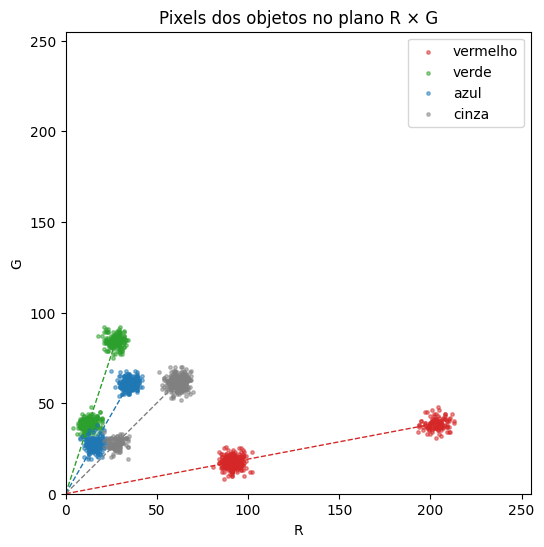

In [7]:
rng = np.random.default_rng(1)
cores_grafico = {"vermelho": "tab:red", "verde": "tab:green", "azul": "tab:blue", "cinza": "gray"}

plt.figure(figsize=(6, 6))
for nome, cor in cores_grafico.items():
    pixels = img_sint[gabarito[nome]]
    amostra = pixels[rng.choice(len(pixels), 400, replace=False)]
    plt.scatter(amostra[:, 0], amostra[:, 1], s=6, color=cor, alpha=0.5, label=nome)
    media_iluminada = img_sint[gabarito[nome] & ~sombra].mean(axis=0)
    plt.plot([0, media_iluminada[0]], [0, media_iluminada[1]], "--", color=cor, linewidth=1)
plt.xlim(0, 255)
plt.ylim(0, 255)
plt.xlabel("R")
plt.ylabel("G")
plt.title("Pixels dos objetos no plano R × G")
plt.legend()
plt.show()

Em RGB, uma cor não é um ponto: ela ocupa uma faixa diagonal que vai até o preto. Isolar "o vermelho" exigiria descrever essa faixa inclinada, e um limiar simples em cada canal só consegue descrever uma caixa alinhada aos eixos. Além disso, perto da origem os grupos de objetos diferentes ficam muito próximos (veja o azul, o verde e o cinza na sombra).

O que precisamos é de uma representação em que **um número diga qual é a cor** e **outro número diga o quanto ela está clara**. É exatamente isso que o modelo HSV faz.

<a id="secao3"></a>

## 3. O modelo HSV e a conversão RGB → HSV

### Teoria: matiz, saturação e valor

O modelo HSV foi proposto por Alvy Ray Smith em 1978 (SMITH, 1978) para descrever as cores de um jeito mais próximo de como as pessoas falam delas. Em vez de "quanto de vermelho, verde e azul", ele separa a cor em três informações:

- **H (*hue*, matiz)**: *qual* é a cor. É um ângulo de 0° a 360° numa roda de cores: 0° é vermelho, 60° amarelo, 120° verde, 180° ciano, 240° azul e 300° magenta. Depois de 360° a roda volta ao vermelho.
- **S (*saturation*, saturação)**: o quanto a cor é **pura**, de 0 a 1. Com S = 0 temos um cinza, e com S = 1 uma cor "forte", sem nada de cinza misturado.
- **V (*value*, valor)**: o quanto a cor é **clara**, de 0 a 1. V = 0 é preto.

Geometricamente, Smith descreveu o HSV como um **cone de base hexagonal** (*hexcone*): o V é a altura, o S é a distância até o eixo central e o H é o ângulo em volta desse eixo. O eixo central (S = 0) corresponde à diagonal dos cinzas do cubo RGB.

A figura abaixo mostra o plano H × S com V = 1. Para desenhá-la usamos a função `hsv_to_rgb` do Matplotlib, que faz o caminho inverso (HSV → RGB). Ela serve só para ilustrar. A conversão que vamos usar no tutorial é implementada por nós mais abaixo.

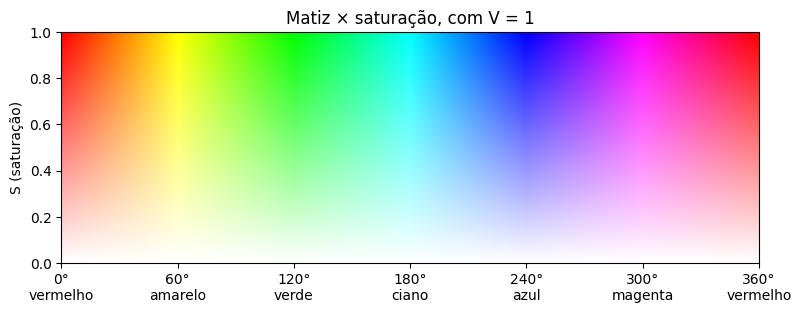

In [8]:
from matplotlib.colors import hsv_to_rgb

h_plano, s_plano = np.meshgrid(np.linspace(0, 1, 361), np.linspace(0, 1, 101))
plano = hsv_to_rgb(np.stack([h_plano, s_plano, np.ones_like(h_plano)], axis=-1))

plt.figure(figsize=(9, 3))
plt.imshow(plano, origin="lower", extent=[0, 360, 0, 1], aspect="auto")
plt.xticks(range(0, 361, 60), ["0°\nvermelho", "60°\namarelo", "120°\nverde",
                               "180°\nciano", "240°\nazul", "300°\nmagenta", "360°\nvermelho"])
plt.ylabel("S (saturação)")
plt.title("Matiz × saturação, com V = 1")
plt.show()

A vantagem para o nosso problema: quando a sombra multiplica $(R, G, B)$ por $k$, **só o V muda**. O H e o S dependem apenas das proporções entre os canais, e essas proporções não mudam. Isso fica claro nas fórmulas.

### As fórmulas da conversão

Primeiro dividimos $R$, $G$ e $B$ por 255, para os valores ficarem entre 0 e 1. Depois calculamos (SMITH, 1978; GONZALEZ; WOODS, 2010):

$$V = \max(R, G, B)$$

$$C = \max(R, G, B) - \min(R, G, B)$$

$$S = \begin{cases} C / V & \text{se } V > 0 \\ 0 & \text{se } V = 0 \end{cases}$$

$$H = 60° \times \begin{cases}
\left(\dfrac{G - B}{C}\right) \bmod 6 & \text{se } \max = R \\[2ex]
\dfrac{B - R}{C} + 2 & \text{se } \max = G \\[2ex]
\dfrac{R - G}{C} + 4 & \text{se } \max = B
\end{cases}
\qquad (H = 0 \text{ se } C = 0)$$

O que cada parte significa:

- **V** é simplesmente o canal mais forte.
- **C** (croma) mede a distância entre o canal mais forte e o mais fraco. Se os três são iguais, $C = 0$ e o pixel é cinza.
- **S** é o croma relativo ao brilho. É por isso que a sombra não altera o S: multiplicando tudo por $k$, $C$ e $V$ são multiplicados por $k$ e o $k$ se cancela na divisão.
- **H** primeiro descobre em qual "terço" da roda a cor está, pelo canal dominante: vermelho perto de 0°, verde perto de 120° (o $+2$, porque $2 \times 60° = 120°$) e azul perto de 240° (o $+4$). Depois desloca o ângulo para um lado ou para o outro, conforme qual dos outros dois canais é mais forte. O $\bmod 6$ só aparece no caso do vermelho: quando $B > G$ a fração fica negativa, e o $\bmod$ leva o resultado para perto de 360° (vermelho puxando para o magenta). No H a sombra também se cancela, porque numerador e denominador são multiplicados pelo mesmo $k$.
- Quando $C = 0$ a matiz não existe (um cinza não tem cor). Por convenção usamos $H = 0$.

### Exemplo feito à mão

Um vermelho iluminado $(200, 50, 50)$ e o mesmo vermelho na sombra, com $k = 0{,}5$: $(100, 25, 25)$.

| | $R, G, B$ (÷255) | $V$ | $C$ | $S = C/V$ | $H$ |
|---|---|---|---|---|---|
| iluminado | 0,784 · 0,196 · 0,196 | 0,784 | 0,588 | **0,75** | $60 \times (0/0{,}588 \bmod 6) =$ **0°** |
| na sombra | 0,392 · 0,098 · 0,098 | 0,392 | 0,294 | **0,75** | $60 \times (0/0{,}294 \bmod 6) =$ **0°** |

O H e o S são idênticos e só o V caiu pela metade. Agora vamos transformar as fórmulas em código.

### Prática 1: conversão de um pixel

A primeira versão segue a fórmula linha por linha, para um único pixel:

In [9]:
def rgb_para_hsv_pixel(r, g, b):
    """Converte um pixel RGB (0 a 255) para (H em graus, S de 0 a 1, V de 0 a 1)."""
    r, g, b = r / 255, g / 255, b / 255
    maximo = max(r, g, b)
    minimo = min(r, g, b)
    c = maximo - minimo

    v = maximo
    s = 0.0 if v == 0 else c / v

    if c == 0:
        h = 0.0
    elif maximo == r:
        h = 60 * (((g - b) / c) % 6)
    elif maximo == g:
        h = 60 * ((b - r) / c + 2)
    else:
        h = 60 * ((r - g) / c + 4)
    return h, s, v


for nome, pixel in [("vermelho iluminado", (200, 50, 50)), ("vermelho na sombra", (100, 25, 25)),
                    ("vermelho puxando p/ magenta", (200, 50, 80)), ("verde", (30, 92, 45)),
                    ("azul", (40, 70, 200)), ("cinza", (75, 75, 75))]:
    h, s, v = rgb_para_hsv_pixel(*pixel)
    print(f"{nome:28s} {str(pixel):16s} -> H = {h:6.1f}°  S = {s:.3f}  V = {v:.3f}")

vermelho iluminado           (200, 50, 50)    -> H =    0.0°  S = 0.750  V = 0.784
vermelho na sombra           (100, 25, 25)    -> H =    0.0°  S = 0.750  V = 0.392
vermelho puxando p/ magenta  (200, 50, 80)    -> H =  348.0°  S = 0.750  V = 0.784
verde                        (30, 92, 45)     -> H =  134.5°  S = 0.674  V = 0.361
azul                         (40, 70, 200)    -> H =  228.8°  S = 0.800  V = 0.784
cinza                        (75, 75, 75)     -> H =    0.0°  S = 0.000  V = 0.294


O resultado bate com a conta feita à mão. Repare em dois casos:

- o vermelho com um pouco mais de azul, $(200, 50, 80)$, ficou com $H = 348°$: é o $\bmod 6$ fazendo a volta na roda. Para o computador, 348° e 0° são números muito diferentes, mas como cores eles são vizinhos. Vamos precisar lembrar disso na segmentação;
- o cinza tem $S = 0$ e $H = 0$ pela convenção. Esse $H = 0$ **não** significa vermelho.

### Prática 2: conversão da imagem inteira com NumPy

A imagem sintética tem $300 \times 480 = 144.000$ pixels, e uma foto de celular tem milhões. Chamar a função acima em um laço `for` funciona, mas é lento em Python. Com NumPy aplicamos cada operação **na matriz inteira de uma vez**:

- `max` e `min` em `axis=-1` calculam o maior e o menor canal de cada pixel;
- para o $S$, `np.divide(..., where=v > 0)` só divide onde $V > 0$ e deixa 0 no resto;
- para o $H$, calculamos as três fórmulas para **todos** os pixels e depois `np.select` escolhe, pixel a pixel, a fórmula certa. As condições são testadas na mesma ordem da versão de um pixel: primeiro $C = 0$, depois máximo em R, depois em G e, se nenhuma valer, B;
- onde $C = 0$ trocamos o divisor por 1 (`c_seguro`), só para não dividir por zero. Nesses pixels o resultado é descartado pelo `np.select` de qualquer forma.

In [10]:
def rgb_para_hsv(img):
    """Converte uma imagem RGB uint8 (altura x largura x 3) para HSV.
    Devolve uma matriz float com H em graus [0, 360), S e V em [0, 1]."""
    rgb = img.astype(np.float64) / 255
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    maximo = rgb.max(axis=-1)
    minimo = rgb.min(axis=-1)
    c = maximo - minimo

    v = maximo
    s = np.divide(c, v, out=np.zeros_like(c), where=v > 0)

    c_seguro = np.where(c > 0, c, 1)
    h_r = 60 * (((g - b) / c_seguro) % 6)
    h_g = 60 * ((b - r) / c_seguro + 2)
    h_b = 60 * ((r - g) / c_seguro + 4)
    h = np.select([c == 0, maximo == r, maximo == g], [0.0, h_r, h_g], default=h_b)

    return np.stack([h, s, v], axis=-1)

In [11]:
import time

inicio = time.perf_counter()
hsv_laco = np.array([[rgb_para_hsv_pixel(*map(int, px)) for px in linha] for linha in img_sint])
tempo_laco = time.perf_counter() - inicio

inicio = time.perf_counter()
hsv_sint = rgb_para_hsv(img_sint)
tempo_numpy = time.perf_counter() - inicio

print(f"Laço pixel a pixel: {tempo_laco * 1000:8.1f} ms")
print(f"NumPy (vetorizado): {tempo_numpy * 1000:8.1f} ms  ({tempo_laco / tempo_numpy:.0f}x mais rápido)")

Laço pixel a pixel:    279.1 ms
NumPy (vetorizado):     22.4 ms  (12x mais rápido)


Os tempos variam de computador para computador, mas a versão vetorizada é sempre bem mais rápida. Na seção 4 conferimos que as duas versões dão exatamente o mesmo resultado.

### Prática 3: os canais H, S e V da imagem sintética

Mostramos o H com um mapa de cores circular (`hsv` do Matplotlib), em que 0° e 360° têm a mesma cor, e o S e o V em escala de cinza.

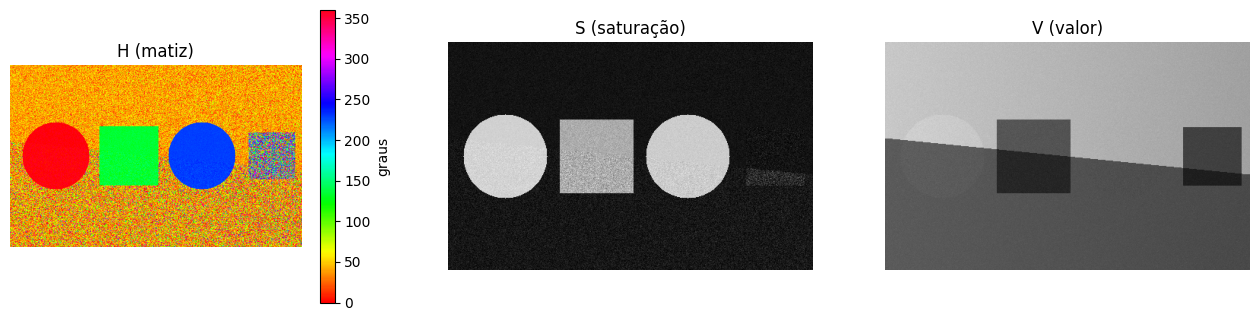

In [12]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 3.8))
im = eixos[0].imshow(hsv_sint[..., 0], cmap="hsv", vmin=0, vmax=360)
fig.colorbar(im, ax=eixos[0], label="graus")
eixos[0].set_title("H (matiz)")
eixos[1].imshow(hsv_sint[..., 1], cmap="gray", vmin=0, vmax=1)
eixos[1].set_title("S (saturação)")
eixos[2].imshow(hsv_sint[..., 2], cmap="gray", vmin=0, vmax=1)
eixos[2].set_title("V (valor)")
for eixo in eixos:
    eixo.axis("off")
plt.show()

O que dá para ver:

- **H**: os círculos vermelho e azul e o quadrado verde têm uma matiz uniforme, **sem nenhum sinal da sombra**. O fundo bege aparece alaranjado e granulado (bege é um laranja com pouca saturação), e o quadrado cinza vira um chuvisco de cores. Isso acontece porque os dois são cinzas ou quase cinzas: com $C$ muito pequeno, o ruído decide qual canal é o maior e a matiz pula de um valor para outro. É por isso que, na segmentação, vamos exigir uma saturação mínima.
- **S**: os três objetos coloridos são claros (saturados). O fundo e o quadrado cinza são escuros (pouco saturados), e a sombra quase não aparece. A exceção é a parte do quadrado cinza na sombra, que ficou um pouco mais clara: num pixel escuro o ruído pesa mais em relação ao $V$ e "inventa" saturação. Por isso, além da saturação mínima, vamos exigir também um valor mínimo.
- **V**: aqui a sombra aparece toda. O V concentrou a informação de brilho, que antes estava espalhada pelos três canais RGB.

Para confirmar com números, medimos H, S e V de cada objeto na parte iluminada e na sombra. Um cuidado: **não dá para fazer a média simples do H**. Os pixels do vermelho ficam em volta de 0°, alguns em 1° e outros em 359°, e a média aritmética daria um valor no meio da roda, longe do vermelho. Usamos então a **média circular**: cada ângulo vira um vetor de tamanho 1, fazemos a média dos vetores e pegamos o ângulo do resultado.

In [13]:
def media_circular(angulos_graus):
    rad = np.deg2rad(angulos_graus)
    return np.rad2deg(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360


print(f"{'região':28s} {'H (°)':>7s} {'S':>6s} {'V':>6s}   {'média simples de H':>18s}")
for nome in ["vermelho", "verde", "azul"]:
    for parte, onde in [("iluminado", ~sombra), ("na sombra", sombra)]:
        h, s, v = hsv_sint[gabarito[nome] & onde].T
        print(f"{nome + ' ' + parte:28s} {media_circular(h):7.1f} {s.mean():6.2f} {v.mean():6.2f}   {h.mean():18.1f}")

região                         H (°)      S      V   média simples de H
vermelho iluminado               0.0   0.82   0.80                159.9
vermelho na sombra               0.0   0.83   0.36                162.9
verde iluminado                134.3   0.67   0.33                134.3
verde na sombra                134.2   0.68   0.15                134.2
azul iluminado                 228.8   0.80   0.68                228.8
azul na sombra                 229.0   0.80   0.31                229.0


Comparando com a tabela RGB da seção 2:

- em RGB, a sombra derrubou os três canais para menos da metade;
- em HSV, a sombra mudou **só o V**. O H e o S de cada objeto ficaram praticamente iguais. As diferenças pequenas vêm do ruído, que pesa mais quando o pixel está escuro.

A última coluna mostra o erro da média simples no vermelho: ela dá cerca de 160° (uma matiz entre verde e ciano), quando o correto é ~0°. Nos outros objetos, que estão longe de 0°/360°, as duas médias coincidem.

Antes de usar essa conversão para segmentar, precisamos ter certeza de que ela está correta.

<a id="secao4"></a>

## 4. Validação da conversão

Uma conversão que "parece certa" nas figuras pode ter erros em casos específicos, como os empates entre canais, os cinzas, o preto ou a volta dos 360°. Por isso conferimos a nossa implementação de quatro formas:

1. **cores conhecidas**, cujo HSV sabemos de cabeça, testadas com `assert` (se alguma falhar, o notebook para com erro);
2. a **versão de um pixel** contra a **versão vetorizada**;
3. a nossa conversão contra o módulo **`colorsys`**, da biblioteca padrão do Python;
4. a nossa conversão contra a função **`cv2.cvtColor`** do OpenCV.

O `colorsys` e o OpenCV entram aqui **somente como referência**, para medir o erro. Eles não são usados na segmentação.

### Teste 1: cores conhecidas

In [14]:
cores_conhecidas = [
    ("vermelho", (255, 0, 0), (0, 1, 1)),
    ("amarelo", (255, 255, 0), (60, 1, 1)),
    ("verde", (0, 255, 0), (120, 1, 1)),
    ("ciano", (0, 255, 255), (180, 1, 1)),
    ("azul", (0, 0, 255), (240, 1, 1)),
    ("magenta", (255, 0, 255), (300, 1, 1)),
    ("laranja", (255, 128, 0), (60 * 128 / 255, 1, 1)),
    ("vermelho escuro", (128, 0, 0), (0, 1, 128 / 255)),
    ("branco", (255, 255, 255), (0, 0, 1)),
    ("cinza", (128, 128, 128), (0, 0, 128 / 255)),
    ("preto", (0, 0, 0), (0, 0, 0)),
]

for nome, rgb, esperado in cores_conhecidas:
    obtido = rgb_para_hsv_pixel(*rgb)
    vetorizado = rgb_para_hsv(np.array([[rgb]], dtype=np.uint8))[0, 0]
    assert np.allclose(obtido, esperado) and np.allclose(vetorizado, esperado), nome
    print(f"{nome:16s} {str(rgb):16s} -> H = {obtido[0]:6.2f}°  S = {obtido[1]:.3f}  V = {obtido[2]:.3f}   ok")

vermelho         (255, 0, 0)      -> H =   0.00°  S = 1.000  V = 1.000   ok
amarelo          (255, 255, 0)    -> H =  60.00°  S = 1.000  V = 1.000   ok
verde            (0, 255, 0)      -> H = 120.00°  S = 1.000  V = 1.000   ok
ciano            (0, 255, 255)    -> H = 180.00°  S = 1.000  V = 1.000   ok
azul             (0, 0, 255)      -> H = 240.00°  S = 1.000  V = 1.000   ok
magenta          (255, 0, 255)    -> H = 300.00°  S = 1.000  V = 1.000   ok
laranja          (255, 128, 0)    -> H =  30.12°  S = 1.000  V = 1.000   ok
vermelho escuro  (128, 0, 0)      -> H =   0.00°  S = 1.000  V = 0.502   ok
branco           (255, 255, 255)  -> H =   0.00°  S = 0.000  V = 1.000   ok
cinza            (128, 128, 128)  -> H =   0.00°  S = 0.000  V = 0.502   ok
preto            (0, 0, 0)        -> H =   0.00°  S = 0.000  V = 0.000   ok


### Teste 2: versão de um pixel × versão vetorizada

Na seção 3 convertemos a imagem sintética das duas formas (`hsv_laco` e `hsv_sint`). Se a vetorização estiver certa, as duas matrizes são iguais.

In [15]:
diferenca = np.abs(hsv_laco - hsv_sint).max()
print("Maior diferença entre as duas versões:", diferenca)
assert diferenca < 1e-12

Maior diferença entre as duas versões: 0.0


### Conjunto de teste para as bibliotecas

Para comparar com as bibliotecas, montamos um conjunto grande de cores:

- todos os pixels da imagem sintética (144.000);
- uma grade regular do cubo RGB, com passo 15 em cada canal ($18^3 = 5.832$ cores, incluindo preto, branco, cinzas e empates entre canais);
- 100.000 cores sorteadas.

As cores ficam numa matriz de uma linha só, porque as funções esperam uma "imagem".

Para comparar o H usamos a **diferença angular**: 359,9° e 0,1° estão a só 0,2° de distância na roda, e não a 359,8°.

In [16]:
def diferenca_angular(a, b):
    d = np.abs(a - b) % 360
    return np.minimum(d, 360 - d)


grade = np.arange(0, 256, 15)
cores_grade = np.stack(np.meshgrid(grade, grade, grade), axis=-1).reshape(-1, 3)
cores_sorteadas = np.random.default_rng(2).integers(0, 256, (100_000, 3))
cores_teste = np.vstack([img_sint.reshape(-1, 3), cores_grade, cores_sorteadas]).astype(np.uint8)

img_teste = cores_teste.reshape(1, -1, 3)
hsv_nosso = rgb_para_hsv(img_teste)[0]
print("Total de cores no teste:", len(cores_teste))


def relatorio(nome, h_ref, s_ref, v_ref):
    erros = {
        "H (graus)": diferenca_angular(hsv_nosso[:, 0], h_ref),
        "S": np.abs(hsv_nosso[:, 1] - s_ref),
        "V": np.abs(hsv_nosso[:, 2] - v_ref),
    }
    print(f"Nossa conversão × {nome}")
    print(f"  {'canal':10s} {'erro máximo':>14s} {'erro médio':>14s}")
    for canal, erro in erros.items():
        print(f"  {canal:10s} {erro.max():14.2e} {erro.mean():14.2e}")
    return erros

Total de cores no teste: 249832


### Teste 3: `colorsys`

O `colorsys.rgb_to_hsv` recebe um pixel com valores de 0 a 1 e devolve H, S e V de 0 a 1. Multiplicamos o H dele por 360 para comparar com o nosso, que está em graus.

In [17]:
import colorsys

ref_colorsys = np.array([colorsys.rgb_to_hsv(*(px / 255)) for px in cores_teste.astype(float)])
erros_colorsys = relatorio("colorsys", ref_colorsys[:, 0] * 360, ref_colorsys[:, 1], ref_colorsys[:, 2])

assert all(erro.max() < 1e-9 for erro in erros_colorsys.values())

Nossa conversão × colorsys
  canal         erro máximo     erro médio
  H (graus)        1.14e-13       6.28e-15
  S                0.00e+00       0.00e+00
  V                0.00e+00       0.00e+00


Os erros ficam na ordem de $10^{-13}$, ou seja, são apenas arredondamentos do ponto flutuante. Na prática os resultados são **idênticos**.

### Teste 4: OpenCV

O `cv2.cvtColor` trabalha em dois modos, e é importante saber a diferença:

- com imagem **`float32`** (valores de 0 a 1), ele devolve H de 0 a 360 e S e V de 0 a 1, a mesma escala que a nossa;
- com imagem **`uint8`** (0 a 255), ele precisa caber o H em 8 bits. Como 360 não cabe em 255, ele guarda **H/2** (0 a 179), e o S e o V vão de 0 a 255. Isso é uma armadilha comum: quem copia limiares de tutoriais do OpenCV precisa lembrar que "H = 90" no OpenCV `uint8` é 180° (ciano).

In [18]:
import cv2

ref_cv = cv2.cvtColor((img_teste / 255).astype(np.float32), cv2.COLOR_RGB2HSV)[0].astype(np.float64)
erros_cv = relatorio("OpenCV (float32)", ref_cv[:, 0], ref_cv[:, 1], ref_cv[:, 2])

assert erros_cv["H (graus)"].max() < 0.01
assert erros_cv["S"].max() < 1e-5 and erros_cv["V"].max() < 1e-5

Nossa conversão × OpenCV (float32)
  canal         erro máximo     erro médio
  H (graus)        1.83e-03       7.03e-05
  S                3.40e-06       9.40e-08
  V                2.97e-08       1.22e-08


Aqui o erro é maior que no `colorsys`, mas continua minúsculo: no máximo milésimos de grau no H. A diferença vem da **precisão**: o OpenCV faz as contas em `float32`, com cerca de 7 dígitos significativos, e nós em `float64`, com cerca de 16. Um erro de 0,002° no H é invisível em qualquer imagem.

Por último, o modo `uint8`. Convertemos o nosso resultado para a escala do OpenCV (H/2 e S, V × 255) e comparamos:

In [19]:
ref_cv8 = cv2.cvtColor(img_teste, cv2.COLOR_RGB2HSV)[0].astype(np.float64)
print("Faixa do OpenCV uint8 (mín, máx):  H", ref_cv8[:, 0].min(), ref_cv8[:, 0].max(),
      "| S", ref_cv8[:, 1].min(), ref_cv8[:, 1].max(), "| V", ref_cv8[:, 2].min(), ref_cv8[:, 2].max())

nosso_na_escala_cv = np.stack([hsv_nosso[:, 0] / 2, hsv_nosso[:, 1] * 255, hsv_nosso[:, 2] * 255], axis=-1)
dif_h = np.abs(nosso_na_escala_cv[:, 0] - ref_cv8[:, 0])
dif_h = np.minimum(dif_h, 180 - dif_h)
dif_s = np.abs(nosso_na_escala_cv[:, 1] - ref_cv8[:, 1])
dif_v = np.abs(nosso_na_escala_cv[:, 2] - ref_cv8[:, 2])
print(f"Maior diferença (em unidades do OpenCV uint8):  H {dif_h.max():.2f}   S {dif_s.max():.2f}   V {dif_v.max():.2f}")

assert dif_h.max() < 1 and dif_s.max() < 1 and dif_v.max() < 1

Faixa do OpenCV uint8 (mín, máx):  H 0.0 179.0 | S 0.0 255.0 | V 0.0 255.0
Maior diferença (em unidades do OpenCV uint8):  H 0.62   S 0.52   V 0.00


As diferenças ficam abaixo de 1 unidade. Elas vêm só do **arredondamento** para números inteiros que o modo `uint8` precisa fazer.

### Resumo da validação

| Teste | Resultado |
|---|---|
| Cores conhecidas (11 casos, incluindo preto, branco e cinza) | todas corretas |
| Versão de um pixel × versão vetorizada | idênticas |
| × `colorsys` (~250 mil cores) | erro ~$10^{-13}$, idênticas |
| × OpenCV `float32` | erro de milésimos de grau, por causa da precisão `float32` |
| × OpenCV `uint8` | diferença < 1 unidade, por causa do arredondamento para inteiro |

Todos os testes usam `assert`: se alguém alterar a função e introduzir um erro, o notebook para nesta seção. Com a conversão validada, podemos usá-la para segmentar.

<a id="secao5"></a>

## 5. Segmentação por faixa de matiz

*Seção em construção.*

<a id="secao6"></a>

## 6. Comparação: a mesma segmentação em RGB

*Seção em construção.*

<a id="secao7"></a>

## 7. Limitações

*Seção em construção.*

<a id="secao8"></a>

## 8. Conclusão

*Seção em construção.*

<a id="secao9"></a>

## 9. Uso de IA

*Seção em construção.*

<a id="secao10"></a>

## 10. Referências

*Seção em construção.*